# Supplementary Figure S10. Interactive FastRNA visualization for targeted structural inspection

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
RENDERS = ROOT / "data" / "pymol" / "renders"
CROPPED = RENDERS / "cropped"
CROPPED.mkdir(parents=True, exist_ok=True)

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def letter(fig, ax, s, dx=-0.012, dy=0.004):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def autocrop(name, pad=2, thresh=246):
    src, dst = RENDERS / name, CROPPED / name
    im = Image.open(src).convert("RGB")
    mask = ImageOps.grayscale(im).point(lambda v: 255 if v < thresh else 0)
    box = mask.getbbox()
    if box:
        l, t, r, b = box
        im = im.crop((max(0, l - pad), max(0, t - pad),
                      min(im.width, r + pad), min(im.height, b + pad)))
    im.save(dst)
    return dst

def show(ax, name):
    ax.imshow(plt.imread(autocrop(f"{name}.png")))
    ax.set_xticks([]); ax.set_yticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)

for n in ("6A", "6B", "6C"):
    im = Image.open(RENDERS / f"{n}.png")
    print(f"{n}: {im.width}x{im.height}px")

from matplotlib.colors import LinearSegmentedColormap

SESSION_GREY = (0.707, 0.707, 0.707)
SEVERITY = LinearSegmentedColormap.from_list(
    "parse_severity", [(1.0, 0.867, 0.0), (1.0, 0.5, 0.0), (1.0, 0.0, 0.0)])
FLAT_GREY = LinearSegmentedColormap.from_list("g", [SESSION_GREY, SESSION_GREY])

def severity_bar(ax, grey_frac=0.22):
    grad = np.linspace(0, 1, 256).reshape(1, -1)
    ax.imshow(np.zeros((1, 32)), extent=(0, grey_frac, 0, 1), aspect="auto", cmap=FLAT_GREY)
    ax.imshow(grad, extent=(grey_frac + 0.02, 1, 0, 1), aspect="auto", cmap=SEVERITY)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_yticks([]); ax.set_xticks([])
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)
    ax.text(grey_frac / 2, -0.6, "preferred", ha="center", va="top", fontsize=7.5, color="0.35")
    ax.text(grey_frac + 0.02, -0.6, "secondary review", ha="left", va="top", fontsize=7.5, color="0.2")
    ax.text(1.0, -0.6, "priority review", ha="right", va="top", fontsize=7.5, color="0.2")

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


6A: 2000x3000px
6B: 3400x2550px
6C: 3400x2550px


## Panel A
Whole-RNA visualization of FastRNA structural-quality assessment


/var/folders/ly/ppp_v4vn4j79kn9bnbf_j2v0gtttsb/T/ipykernel_66104/3810600823.py:8: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


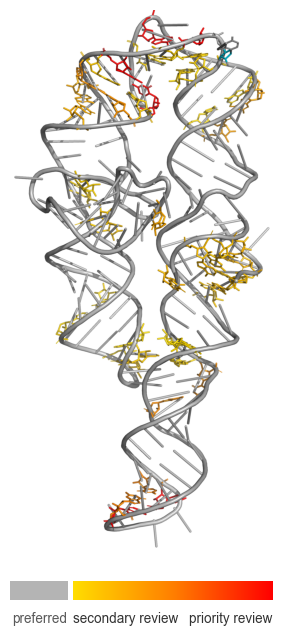

In [2]:
def draw_a(ax):
    show(ax, "6A")

fig, (ax, cax) = plt.subplots(2, 1, figsize=(2.6, 5.9),
                              gridspec_kw={"height_ratios": [1, 0.035], "hspace": 0.12})
draw_a(ax)
severity_bar(cax)
fig.tight_layout()
save(fig, "figures/supplemental/figS10_A_whole_rna.png")
plt.show()


## Panel B
Zoomed local interaction with reference-geometry comparison


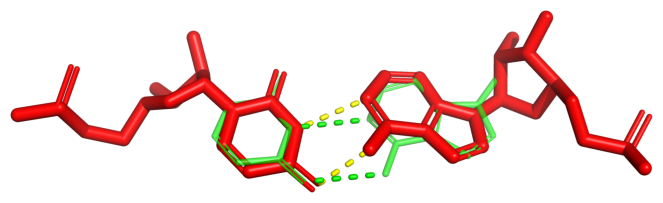

In [3]:
def draw_b(ax):
    show(ax, "6B")

fig, ax = plt.subplots(figsize=(5.2, 2.2))
draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS10_B_local_interaction.png")
plt.show()


## Panel C
Second local interaction illustrating a different structural defect


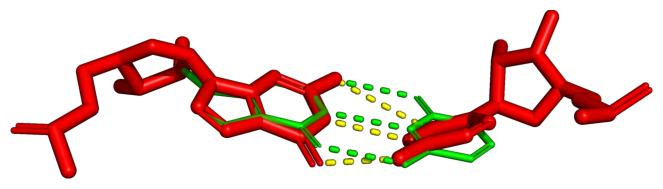

In [4]:
def draw_c(ax):
    show(ax, "6C")

fig, ax = plt.subplots(figsize=(5.2, 2.2))
draw_c(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS10_C_local_interaction.png")
plt.show()


## Combined figure


saved 5.15 x 4.02 in; at 6.73 in wide the smallest text prints at 7.00 pt, height 4.02 in


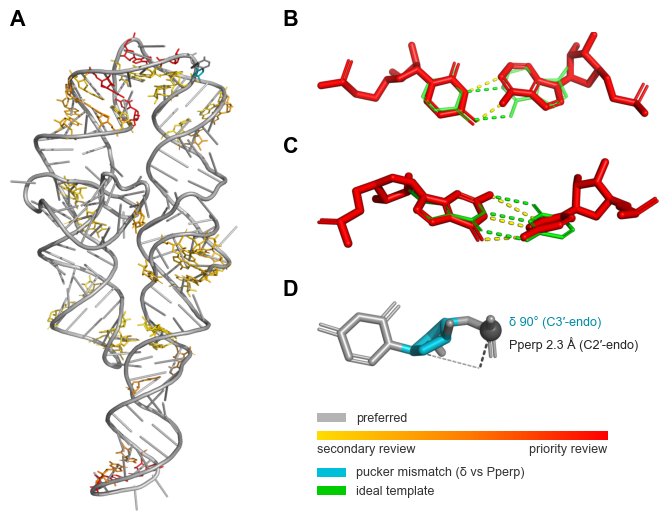

In [5]:
import json
FIG_W, FIG_H = 7.2, 3.35
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
aspect = lambda n: (lambda im: im.width / im.height)(Image.open(CROPPED / f"{n}.png"))

draw_a(fig.add_axes([0, 0, 0.1, 0.1]))
plt.close(fig)
fig = plt.figure(figsize=(FIG_W, FIG_H))

_widest = max(Image.open(CROPPED / f"{n}.png").size[0] for n in ("6B", "6C"))
RENDER_SCALE = 2.63 / _widest
b_w, b_h = (n * RENDER_SCALE for n in Image.open(CROPPED / "6B.png").size)
c_w, c_h = (n * RENDER_SCALE for n in Image.open(CROPPED / "6C.png").size)
D_ZOOM = 1.2
d_w, d_h = (n * RENDER_SCALE * D_ZOOM for n in Image.open(autocrop("7D.png")).size)
GAP = float(globals().get('F7_GAP', 0.25))
CD_EXTRA = 0.20
KEY_GAP = float(globals().get('F7_KEY_GAP', 0.30))
KEY_H = 0.14 + 0.07 + 0.21 + 0.14 + 0.07 + 0.12
A_H, COL_A = b_h + GAP + c_h + GAP + CD_EXTRA + d_h + KEY_GAP + KEY_H, 2.45
a_w = A_H * aspect("6A")
ax_a = fig.add_axes(inch(0.15, 0.30, a_w, A_H))
RIGHT_X = 0.15 + a_w + float(globals().get('F7_HGAP', 0.35)) + 0.26
top_b = 0.30
ax_b = fig.add_axes(inch(RIGHT_X, top_b, b_w, b_h))
ax_c = fig.add_axes(inch(RIGHT_X, top_b + b_h + GAP, c_w, c_h))
ax_d = fig.add_axes(inch(RIGHT_X, top_b + b_h + GAP + c_h + GAP + CD_EXTRA - 0.04, d_w, d_h))
KEY_W = 2 * 0.85 * max(b_w, c_w, d_w)
KEY_Y = top_b + b_h + GAP + c_h + GAP + CD_EXTRA + d_h + KEY_GAP
KEY_X = RIGHT_X
ax_pref = fig.add_axes(inch(KEY_X, KEY_Y, 0.22, 0.07))
ax_bar = fig.add_axes(inch(KEY_X, KEY_Y + 0.14, KEY_W / 2, 0.07))
ax_pk = fig.add_axes(inch(KEY_X, KEY_Y + 0.14 + 0.07 + 0.21, 0.22, 0.07))
ax_tm = fig.add_axes(inch(KEY_X, KEY_Y + 0.14 + 0.07 + 0.21 + 0.14, 0.22, 0.07))

draw_a(ax_a)
ax_pref.add_patch(plt.Rectangle((0, 0), 1, 1, color=SESSION_GREY))
ax_pref.text(1.35, 0.5, "preferred", ha="left", va="center", color="0.2")
ax_bar.imshow(np.linspace(0, 1, 256).reshape(1, -1), extent=(0, 1, 0, 1), aspect="auto", cmap=SEVERITY)
ax_bar.text(0.0, -0.3, "secondary review", ha="left", va="top", color="0.2")
ax_bar.text(1.0, -0.3, "priority review", ha="right", va="top", color="0.2")
for _ax in (ax_pref, ax_bar):
    _ax.set_xlim(0, 1); _ax.set_ylim(0, 1); _ax.axis("off")
draw_b(ax_b)
draw_c(ax_c)
show(ax_d, "7D")
_lab = json.loads((RENDERS / "7D_labels.json").read_text())
_h, _w = ax_d.images[0].get_array().shape[:2]
_x = 1.04 * _w
ax_d.text(_x, 0.30 * _h, "\u03b4 90\u00b0 (C3\u2032-endo)", ha="left", va="center",
          color=(0.0, 0.55, 0.65), fontsize=7, clip_on=False)
ax_d.text(_x, 0.62 * _h, "Pperp 2.3 \u00c5 (C2\u2032-endo)", ha="left", va="center",
          color="0.15", fontsize=7, clip_on=False)
ax_pk.add_patch(plt.Rectangle((0, 0), 1, 1, color=(0.0, 0.75, 0.85)))
ax_pk.set_xlim(0, 1); ax_pk.set_ylim(0, 1); ax_pk.axis("off")
ax_pk.text(1.35, 0.5, "pucker mismatch (\u03b4 vs Pperp)", ha="left", va="center", fontsize=7.5, color="0.2")
ax_tm.add_patch(plt.Rectangle((0, 0), 1, 1, color=(0.0, 0.80, 0.0)))
ax_tm.set_xlim(0, 1); ax_tm.set_ylim(0, 1); ax_tm.axis("off")
ax_tm.text(1.35, 0.5, "ideal template", ha="left", va="center", fontsize=7.5, color="0.2")

for ax, s, x in ((ax_a, "A", 0.15 / FIG_W), (ax_b, "B", None), (ax_c, "C", None), (ax_d, "D", None)):
    box = ax.get_position()
    fig.text(box.x0 - 0.02 if x is None else x, box.y1 + 0.005, s, fontsize=12,
             fontweight="bold", ha="right" if x is None else "left", va="bottom")

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)


def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

save(fig, "figures/supplemental/figS10.png")
plt.show()